# MiniVLA: from pixels and language to robot actions

A visual tour of the synthetic tabletop dataset and the 281K-parameter Vision-Language-Action policy.

**What this notebook shows**

- independently generated train, validation, and held-out test scenes;
- the explicit expert action and gripper conventions;
- a real checkpoint prediction; and
- numerical equivalence of reference attention and PyTorch SDPA.

> All examples are deterministic under seed 1337. No training is performed here.

In [1]:
from pathlib import Path
import sys
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib', 'inline')
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.dataset import SyntheticTabletopDataset
from src.evaluate import load_trained_model
from src.utils import load_config, parameter_count, seed_everything

config = load_config(ROOT / 'configs' / 'default.yaml')
seed_everything(int(config['seed']))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root: {ROOT}')
print(f'PyTorch: {torch.__version__} | Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name()} | BF16: {torch.cuda.is_bf16_supported()}')

Project root: S:\Code\MiniVLA
PyTorch: 2.11.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 3060 | BF16: True


## 1. Deterministic data with a real distribution shift

Training and validation targets live in the tabletop interior. Test targets are deliberately placed in held-out edge bands and also vary object size and background color. The expert emits bounded motion toward the instructed object; gripper **0 means open** and **1 means closed**.

In [2]:
datasets = {
    'train': SyntheticTabletopDataset.from_config(config, 'train', size=128),
    'validation': SyntheticTabletopDataset.from_config(config, 'val', size=64),
    'test': SyntheticTabletopDataset.from_config(config, 'test', size=64),
}

def split_summary(dataset):
    targets = torch.stack([dataset[i]['target_position'] for i in range(len(dataset))])
    actions = torch.stack([dataset[i]['action'] for i in range(len(dataset))])
    return {
        'samples': len(dataset),
        'target_x': (float(targets[:, 0].min()), float(targets[:, 0].max())),
        'target_y': (float(targets[:, 1].min()), float(targets[:, 1].max())),
        'closed_%': 100.0 * float(actions[:, 2].mean()),
    }

print(f"{'split':<12} {'n':>5} {'target x range':>20} {'target y range':>20} {'closed':>9}")
for name, dataset in datasets.items():
    item = split_summary(dataset)
    print(f"{name:<12} {item['samples']:>5} {str(tuple(round(v, 3) for v in item['target_x'])):>20} "
          f"{str(tuple(round(v, 3) for v in item['target_y'])):>20} {item['closed_%']:>8.1f}%")

train_signatures = {repr(datasets['train'].scene(i)) for i in range(len(datasets['train']))}
test_signatures = {repr(datasets['test'].scene(i)) for i in range(len(datasets['test']))}
print(f'Exact train/test scene overlap: {len(train_signatures & test_signatures)}')

split            n       target x range       target y range    closed
train          128       (0.217, 0.785)       (0.208, 0.801)     34.4%
validation      64       (0.182, 0.799)       (0.214, 0.788)     26.6%
test            64       (0.093, 0.929)       (0.071, 0.913)     28.1%
Exact train/test scene overlap: 0


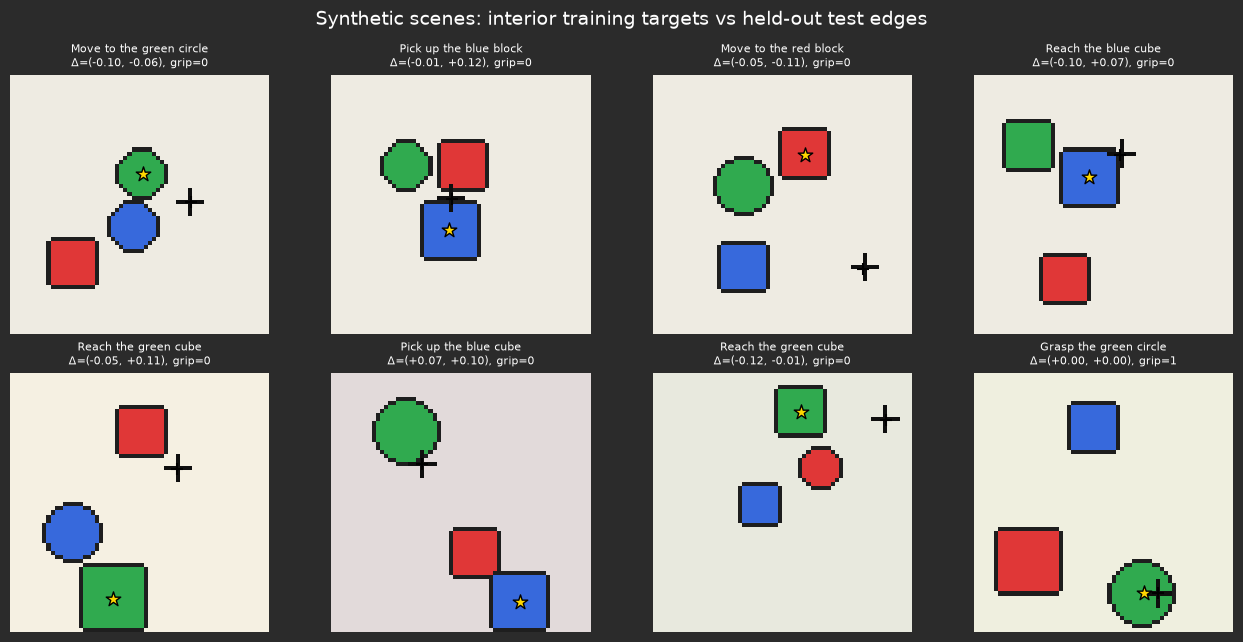

In [3]:
figure, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for row, (split, dataset) in enumerate((('train', datasets['train']), ('held-out test', datasets['test']))):
    for column in range(4):
        sample = dataset[column]
        axis = axes[row, column]
        axis.imshow(sample['image'].permute(1, 2, 0))
        target = sample['target_position'].numpy() * 63
        state = sample['state'].numpy() * 63
        axis.scatter(target[0], target[1], marker='*', s=120, c='gold', edgecolors='black', label='target')
        axis.scatter(state[0], state[1], marker='+', s=80, c='black', label='end effector')
        action = sample['action'].numpy()
        axis.set_title(f"{sample['instruction']}\nΔ=({action[0]:+.2f}, {action[1]:+.2f}), grip={action[2]:.0f}", fontsize=8)
        axis.axis('off')
    axes[row, 0].set_ylabel(split, fontsize=11)
figure.suptitle('Synthetic scenes: interior training targets vs held-out test edges', fontsize=14)
figure.tight_layout()
plt.show()

## 2. A compact multimodal policy

The network combines 16 spatial CNN tokens, one GRU language token, and one robot-state token with a learned classification token. Two self-attention blocks fuse the modalities before a bounded action head predicts motion and gripper probability.

In [4]:
model = load_trained_model(config, device, attention='reference')
model.eval()
print(model)
print(f'\nTrainable parameters: {parameter_count(model):,}')

samples = [datasets['test'][i] for i in range(4)]
images = torch.stack([sample['image'] for sample in samples]).to(device)
token_ids = torch.stack([sample['token_ids'] for sample in samples]).to(device)
token_mask = torch.stack([sample['token_mask'] for sample in samples]).to(device)
states = torch.stack([sample['state'] for sample in samples]).to(device)
with torch.inference_mode():
    predictions = model.predict_actions(images, token_ids, token_mask, states).float().cpu()

print(f"\n{'instruction':<29} {'expert action':>27} {'model prediction':>27}")
for sample, prediction in zip(samples, predictions):
    expert = tuple(round(float(value), 3) for value in sample['action'])
    predicted = tuple(round(float(value), 3) for value in prediction)
    print(f"{sample['instruction']:<29} {str(expert):>27} {str(predicted):>27}")

MiniVLA(
  (vision): VisionEncoder(
    (features): Sequential(
      (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(24, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (4): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): Conv2d(48, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
      (7): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (8): ReLU(inplace=True)
      (9): AdaptiveAvgPool2d(output_size=(4, 4))
    )
  )
  (language): LanguageEncoder(
    (embedding): Embedding(15, 96, padding_idx=0)
    (gru): GRU(96, 96, batch_first=True)
  )
  (state): Sequential(
    (0): Linear(in_features=2, out_features=96, bias=True)
    (1): ReLU()
    (2): Linear(in_features=96, out_features=96, bias=True)


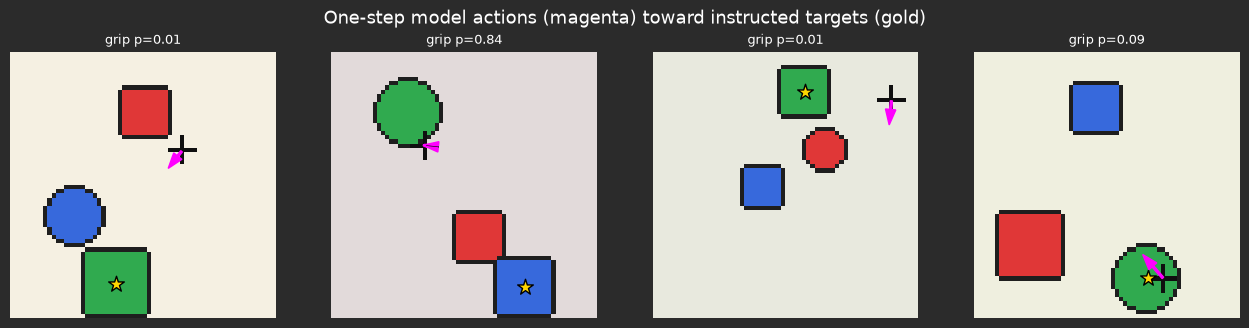

In [5]:
figure, axes = plt.subplots(1, 4, figsize=(13, 3.3))
for axis, sample, prediction in zip(axes, samples, predictions):
    axis.imshow(sample['image'].permute(1, 2, 0))
    state = sample['state'].numpy() * 63
    target = sample['target_position'].numpy() * 63
    predicted_delta = prediction[:2].numpy() * 63
    axis.scatter(target[0], target[1], marker='*', s=140, c='gold', edgecolors='black')
    axis.arrow(state[0], state[1], predicted_delta[0], predicted_delta[1], color='magenta', width=0.5,
               head_width=2.5, length_includes_head=True)
    axis.set_title(f"grip p={prediction[2]:.2f}", fontsize=9)
    axis.axis('off')
figure.suptitle('One-step model actions (magenta) toward instructed targets (gold)', fontsize=13)
figure.tight_layout()
plt.show()

## 3. One set of attention weights, two kernel paths

The reference implementation explicitly materializes scores, softmax probabilities, and value products. The SDPA path calls PyTorch's fused attention interface with the **same learned weights**. In evaluation mode they should agree up to floating-point rounding.

In [6]:
model.set_attention_implementation('reference')
with torch.inference_mode():
    reference_predictions = model.predict_actions(images, token_ids, token_mask, states).float()
model.set_attention_implementation('sdpa')
with torch.inference_mode():
    sdpa_predictions = model.predict_actions(images, token_ids, token_mask, states).float()
absolute_difference = (reference_predictions - sdpa_predictions).abs()
print(f'Max absolute difference:  {absolute_difference.max().item():.8f}')
print(f'Mean absolute difference: {absolute_difference.mean().item():.8f}')
print('All finite:', bool(torch.isfinite(sdpa_predictions).all()))

Max absolute difference:  0.00000002
Mean absolute difference: 0.00000001
All finite: True


### Takeaway

MiniVLA is intentionally small enough to understand end to end, while still exercising the same systems levers—mixed precision, attention dispatch, and compilation—that matter in much larger VLA policies. Continue with **02_optimization_results.ipynb** for the measured GPU story.